# Exploración y diagnóstico del conjunto de datos
**Diego Salinas Laguna**  
Universidad Tecnológica de Tula-Tepeji  
Extracción de Conocimiento en Bases de Datos · Recursamiento 2026 · Unidad II · AE1

Proyecto: Mantenimiento predictivo de maquinaria industrial.

Este trabajo explora y diagnostica. No elimina, imputa ni sustituye datos originales. Ejecutar todas las celdas en orden con Python, Pandas y Matplotlib.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import hashlib
from IPython.display import display
raiz = Path.cwd() if (Path.cwd()/"data/raw/ai4i2020.csv").exists() else Path.cwd().parent
archivo = raiz / "data/raw/ai4i2020.csv"
hash_inicial = hashlib.sha256(archivo.read_bytes()).hexdigest()
df = pd.read_csv(archivo)
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False})

## 1. Identificación y fuente
AI4I 2020 Predictive Maintenance Dataset, UCI (2020), CSV estructurado. Fuente: https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset · DOI: https://doi.org/10.24432/C5HS5C · licencia CC BY 4.0.

Son datos sintéticos generados para representar condiciones industriales, no lecturas directas de sensores de una fábrica. Incluyen mediciones que imitan sensores, una variante de producto y etiquetas de fallas. El proyecto busca identificar condiciones relacionadas con fallas, estimar torque y encontrar perfiles de operación. UCI presenta seis predictores; el CSV completo incluye 14 columnas al contar identificadores y etiquetas.

## 2. Primeras filas

In [2]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


**Interpretación.** head() muestra cinco ejemplos: identificadores, calidad del producto, mediciones y estados de falla. Es una vista inicial, no representa toda la distribución.

## 2. Dimensiones

In [3]:
df.shape

(10000, 14)

**Interpretación.** shape devuelve (10000, 14): diez mil filas y catorce columnas. Cada fila es una observación; no debe asumirse que es una máquina diferente.

## 2. Nombres de columnas

In [4]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

**Interpretación.** columns permite revisar los nombres exactos y sus unidades. Los espacios y corchetes forman parte del nombre.

## 2. Información general

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

**Interpretación.** info() muestra 10,000 valores no nulos por columna y tipos numéricos o texto. No hay columna de fecha; el orden de filas no demuestra intervalos temporales reales.

## 2. Tipos de datos

In [6]:
df.dtypes

UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

**Interpretación.** Los enteros incluyen identificadores y etiquetas binarias; tener tipo numérico no convierte esas columnas en mediciones continuas. Product ID y Type son texto; Pandas puede mostrarlos como str u object según la versión.

## 2. Resumen estadístico

In [7]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


**Interpretación.** describe() resume columnas numéricas. La media de Machine failure es 0.0339, que equivale a 3.39% de fallas. La media de UDI carece de utilidad física.

## 3. Diccionario completo
Type representa calidad baja, media y alta (L, M, H): hay un orden conceptual, pero no se supone una distancia numérica igual entre variantes. Las variables TWF/HDF/PWF/OSF/RNF son etiquetas, no predictores para anticipar Machine failure.

In [8]:
diccionario = pd.DataFrame([['UDI', 'Identificador de fila', 'int64', 'Cualitativa', 'Nominal (identificador)', 'Sin unidad', 'Localizar registros; excluir de modelos'], ['Product ID', 'Código del producto y variante', 'str/object', 'Cualitativa', 'Nominal (identificador)', 'Sin unidad', 'Trazabilidad; excluir de modelos'], ['Type', 'Variante de calidad L, M o H', 'str/object', 'Cualitativa', 'Ordinal conceptual', 'L/M/H', 'Comparar variantes; codificar sin imponer distancias'], ['Air temperature [K]', 'Temperatura del ambiente', 'float64', 'Cuantitativa', 'Continua', 'K', 'Explicar condiciones de operación'], ['Process temperature [K]', 'Temperatura durante el proceso', 'float64', 'Cuantitativa', 'Continua', 'K', 'Explicar condiciones de operación'], ['Rotational speed [rpm]', 'Velocidad de rotación', 'int64', 'Cuantitativa', 'Discreta', 'rpm', 'Explicar condiciones de operación'], ['Torque [Nm]', 'Fuerza de giro', 'float64', 'Cuantitativa', 'Continua', 'Nm', 'Explicar condiciones de operación'], ['Tool wear [min]', 'Tiempo acumulado de uso de la herramienta', 'int64', 'Cuantitativa', 'Discreta', 'min', 'Explicar condiciones de operación'], ['Machine failure', 'Estado general de falla', 'int64', 'Cualitativa', 'Binaria', '0=no; 1=sí', 'Objetivo de clasificación'], ['TWF', 'Falla por desgaste de herramienta', 'int64', 'Cualitativa', 'Binaria', '0=no; 1=sí', 'Diagnóstico; excluir como entrada al predecir falla'], ['HDF', 'Falla por disipación de calor', 'int64', 'Cualitativa', 'Binaria', '0=no; 1=sí', 'Diagnóstico; excluir como entrada al predecir falla'], ['PWF', 'Falla por potencia', 'int64', 'Cualitativa', 'Binaria', '0=no; 1=sí', 'Diagnóstico; excluir como entrada al predecir falla'], ['OSF', 'Falla por sobreesfuerzo', 'int64', 'Cualitativa', 'Binaria', '0=no; 1=sí', 'Diagnóstico; excluir como entrada al predecir falla'], ['RNF', 'Falla aleatoria', 'int64', 'Cualitativa', 'Binaria', '0=no; 1=sí', 'Diagnóstico; excluir como entrada al predecir falla']], columns=['Variable', 'Descripción', 'Tipo Python', 'Tipo variable', 'Clasificación', 'Unidad', 'Utilidad'])
display(diccionario)

,Variable,Descripción,Tipo Python,Tipo variable,Clasificación,Unidad,Utilidad
0,UDI,Identificador de fila,int64,Cualitativa,Nominal (identificador),Sin unidad,Localizar registros; excluir de modelos
1,Product ID,Código del producto y variante,str/object,Cualitativa,Nominal (identificador),Sin unidad,Trazabilidad; excluir de modelos
2,Type,"Variante de calidad L, M o H",str/object,Cualitativa,Ordinal conceptual,L/M/H,Comparar variantes; codificar sin imponer dist...
3,Air temperature [K],Temperatura del ambiente,float64,Cuantitativa,Continua,K,Explicar condiciones de operación
4,Process temperature [K],Temperatura durante el proceso,float64,Cuantitativa,Continua,K,Explicar condiciones de operación
5,Rotational speed [rpm],Velocidad de rotación,int64,Cuantitativa,Discreta,rpm,Explicar condiciones de operación
6,Torque [Nm],Fuerza de giro,float64,Cuantitativa,Continua,Nm,Explicar condiciones de operación
7,Tool wear [min],Tiempo acumulado de uso de la herramienta,int64,Cuantitativa,Discreta,min,Explicar condiciones de operación
8,Machine failure,Estado general de falla,int64,Cualitativa,Binaria,0=no; 1=sí,Objetivo de clasificación
9,TWF,Falla por desgaste de herramienta,int64,Cualitativa,Binaria,0=no; 1=sí,Diagnóstico; excluir como entrada al predecir ...


## 4. Diagnóstico de calidad: faltantes

In [9]:
faltantes = pd.DataFrame({"Cantidad":df.isnull().sum(), "Porcentaje":df.isnull().mean()*100})
display(faltantes)

,Cantidad,Porcentaje
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


**Interpretación.** Todas las columnas tienen 0 faltantes (0%). No se requiere imputación ahora. En otra etapa, si aparecen faltantes en nuevas observaciones, revisar su causa; estimar cualquier valor de reemplazo solo con entrenamiento y no imputar etiquetas de falla.

In [10]:
print("Filas completas duplicadas:", df.duplicated().sum())
print("UDI repetido:", df["UDI"].duplicated().sum())
print("Product ID repetido:", df["Product ID"].duplicated().sum())
print("Duplicados sin identificadores:", df.drop(columns=["UDI","Product ID"]).duplicated().sum())

Filas completas duplicadas: 0
UDI repetido: 0
Product ID repetido: 0
Duplicados sin identificadores: 0


**Interpretación.** Una fila repetida podría deberse a importación doble. Se revisan también identificadores y contenido sin identificadores para evitar que UDI oculte repeticiones. No se elimina ninguna fila; si aparecieran coincidencias se comprobaría si son observaciones distintas o duplicación de carga.

In [11]:
numericas = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
modos = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
validaciones = {"UDI fuera de 1..10000": (~df["UDI"].between(1,10000)).sum(), "Type fuera de L/M/H": (~df["Type"].isin(["L","M","H"])).sum(), "Prefijo de Product ID distinto de Type": df["Product ID"].str[0].ne(df["Type"]).sum(), "Temperaturas no positivas (K)": (df[numericas[:2]]<=0).any(axis=1).sum(), "Velocidad o torque no positivos": (df[numericas[2:4]]<=0).any(axis=1).sum(), "Desgaste negativo": (df["Tool wear [min]"]<0).sum(), "Temperatura proceso menor que aire": (df[numericas[1]]<df[numericas[0]]).sum(), "Etiquetas fuera de 0/1": (~df[["Machine failure"]+modos].isin([0,1])).any(axis=1).sum(), "Mediciones no finitas": (~np.isfinite(df[numericas])).any(axis=1).sum()}
display(pd.Series(validaciones, name="Casos"))
union_modos = df[modos].max(axis=1)
inconsistencias = df["Machine failure"].ne(union_modos)
display(pd.crosstab(df["Machine failure"], union_modos, rownames=["Machine failure"], colnames=["Algún modo activo"]))
display(df.loc[inconsistencias, ["UDI","Machine failure"]+modos])

UDI fuera de 1..10000                     0
Type fuera de L/M/H                       0
Prefijo de Product ID distinto de Type    0
Temperaturas no positivas (K)             0
Velocidad o torque no positivos           0
Desgaste negativo                         0
Temperatura proceso menor que aire        0
Etiquetas fuera de 0/1                    0
Mediciones no finitas                     0
Name: Casos, dtype: int64

Algún modo activo,0,1
Machine failure,,
0,9643,18
1,9,330


,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


**Interpretación.** Las comprobaciones básicas de dominio no detectan valores inválidos. No existen fechas para validar ni límites operativos de una máquina real. Hay **27 discrepancias** entre la etiqueta general y la unión de modos; se revisarán con la fuente, sin cambiar etiquetas automáticamente. UCI describe que cualquier modo activo produce falla, pero el archivo no siempre cumple esa relación; la documentación también refiere cinco fallas aleatorias mientras el CSV contiene 19 RNF. Debe conservarse esta diferencia entre descripción y archivo.

In [12]:
display(df["Type"].value_counts())
display(df["Machine failure"].value_counts().to_frame("Cantidad").assign(Porcentaje=lambda x:x["Cantidad"]/len(df)*100))
display(df[modos].sum().to_frame("Casos por modo"))

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

,Cantidad,Porcentaje
Machine failure,,
0,9661,96.61
1,339,3.39


,Casos por modo
TWF,46
HDF,115
PWF,95
OSF,98
RNF,19


**Interpretación.** Hay 9,661 observaciones sin falla y 339 con falla. Predecir siempre “sin falla” acertaría 96.61%, pero no detectaría ninguna falla; por eso la exactitud aislada sería engañosa. Un registro puede tener varios modos de falla, de modo que sus conteos no deben sumarse como si fueran grupos separados.

## 5. Estadística inicial de cinco mediciones

In [13]:
estadisticas = df[numericas].agg(["mean","median","min","max","std"]).T
display(estadisticas.round(3))

,mean,median,min,max,std
Air temperature [K],300.005,300.1,295.3,304.5,2.000
Process temperature [K],310.006,310.1,305.7,313.8,1.484
Rotational speed [rpm],1538.776,1503.0,1168.0,2886.0,179.284
Torque [Nm],39.987,40.1,3.8,76.6,9.969
Tool wear [min],107.951,108.0,0.0,253.0,63.654


**Interpretación.** El aire se concentra alrededor de 300 K y el proceso alrededor de 310 K. El torque medio es 39.987 Nm y su desviación es 9.969 Nm; hay diferencias de esfuerzo entre observaciones. La velocidad media (1538.776 rpm) supera la mediana (1503 rpm), señal de una cola hacia valores altos. El desgaste va de 0 a 253 minutos: cero puede reflejar herramienta nueva; la dispersión no demuestra por sí sola una falla.

## 6. Valores atípicos: regla de 1.5 IQR
Se calculan Q1, Q3 y límites Q1−1.5×IQR y Q3+1.5×IQR. Es una alerta estadística y no un límite de seguridad de la máquina.

,Variable,Inferior,Superior,Atípicos
0,Air temperature [K],293.50,306.30,0
1,Process temperature [K],305.35,314.55,0
2,Rotational speed [rpm],1139.50,1895.50,418
3,Torque [Nm],12.80,67.20,69
4,Tool wear [min],-110.50,325.50,0


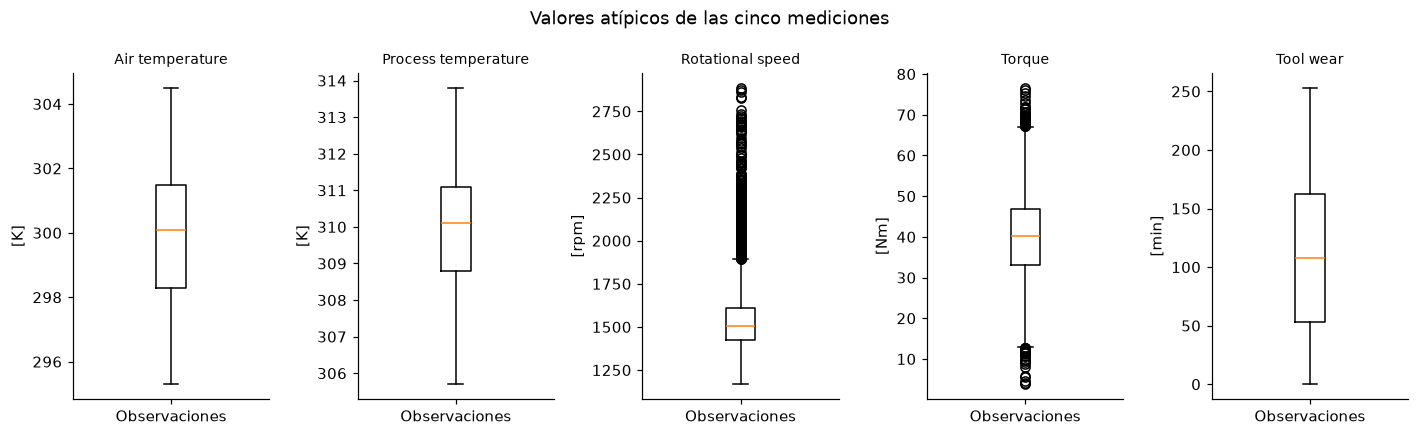

In [14]:
resultados = []
for col in numericas:
    q1, q3 = df[col].quantile([.25,.75])
    iqr = q3-q1
    inferior, superior = q1-1.5*iqr, q3+1.5*iqr
    resultados.append([col,inferior,superior,int(((df[col]<inferior)|(df[col]>superior)).sum())])
display(pd.DataFrame(resultados,columns=["Variable","Inferior","Superior","Atípicos"]).round(3))
fig, axes = plt.subplots(1,5,figsize=(13,4))
for ax,col in zip(axes,numericas):
    ax.boxplot(df[col],tick_labels=["Observaciones"])
    ax.set_title(col.split(" [")[0], fontsize=9)
    ax.set_ylabel(col[col.find("["):])
fig.suptitle("Valores atípicos de las cinco mediciones")
fig.tight_layout()
plt.show()

**Interpretación.** Air temperature [K]: 0 atípicos; Process temperature [K]: 0 atípicos; Rotational speed [rpm]: 418 atípicos; Torque [Nm]: 69 atípicos; Tool wear [min]: 0 atípicos. Las temperaturas y el desgaste no presentan alertas IQR. La velocidad y el torque sí tienen valores extremos; pueden ser condiciones válidas de operación relacionadas con fallas. Se conservarán y revisarán antes de decidir transformaciones o métodos menos sensibles a extremos. No se borran ni recortan datos en esta actividad.

## 7. Visualizaciones iniciales

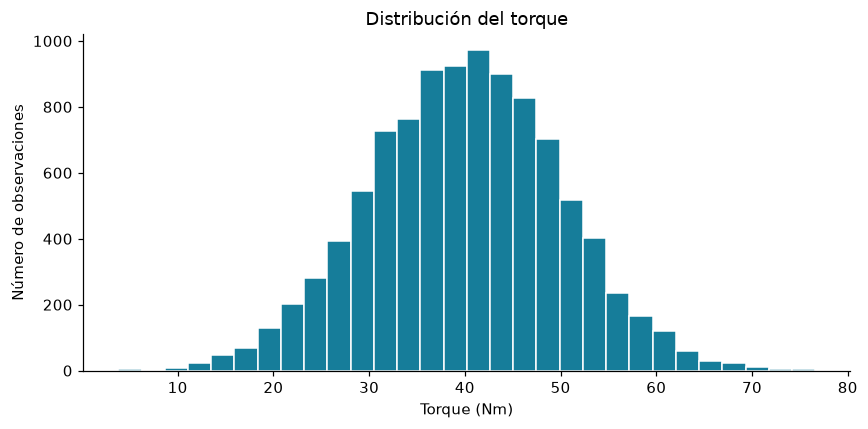

In [15]:
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(df["Torque [Nm]"],bins=30,color="#167D9A",edgecolor="white")
ax.set(title="Distribución del torque",xlabel="Torque (Nm)",ylabel="Número de observaciones")
fig.tight_layout()
plt.show()

**Interpretación.** La mayor concentración de torque está cerca de 40 Nm. Los valores bajos y altos son menos comunes; su rareza no basta para llamarlos errores.

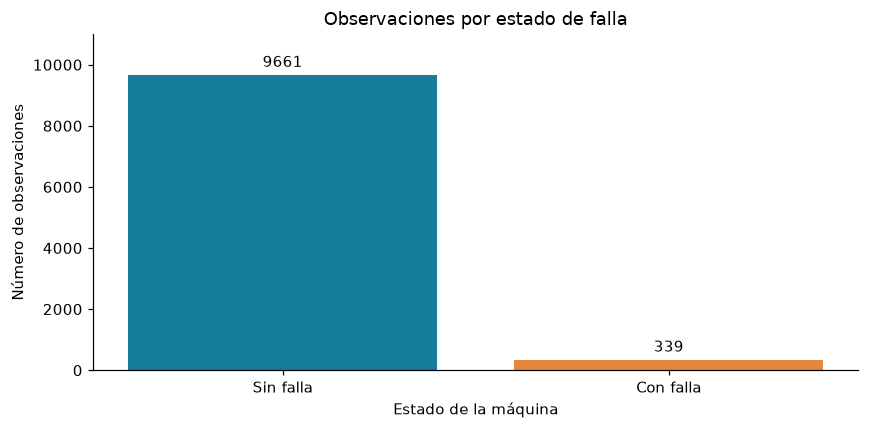

In [16]:
fig, ax = plt.subplots(figsize=(8,4))
conteos = df["Machine failure"].value_counts().reindex([0,1])
barras = ax.bar(["Sin falla","Con falla"],conteos,color=["#167D9A","#E6873C"])
ax.bar_label(barras,padding=3)
ax.set(title="Observaciones por estado de falla",xlabel="Estado de la máquina",ylabel="Número de observaciones",ylim=(0,11000))
fig.tight_layout()
plt.show()

**Interpretación.** La diferencia 9,661 frente a 339 evidencia el desbalance. En la etapa de clasificación habrá que comprobar cuántas fallas detecta el modelo y cuántas falsas alarmas produce.

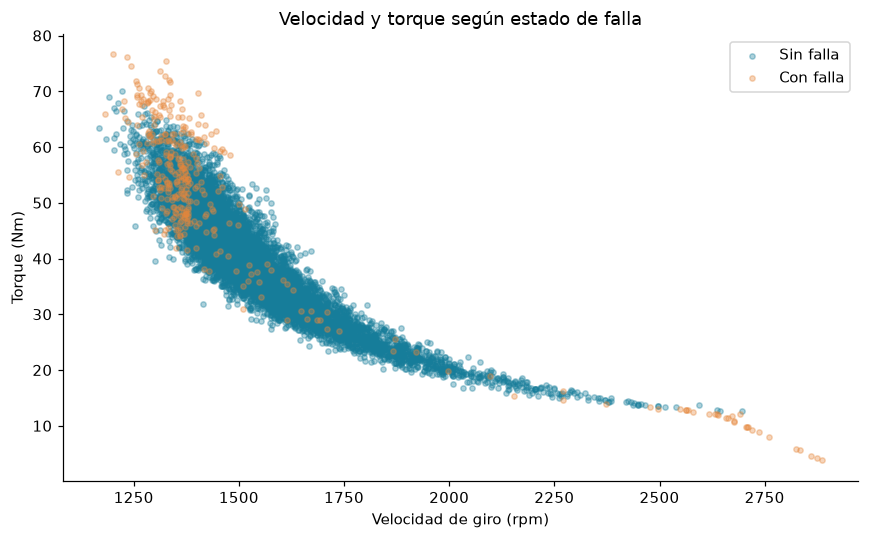

In [17]:
fig, ax = plt.subplots(figsize=(8,5))
for estado,color,nombre in [(0,"#167D9A","Sin falla"),(1,"#E6873C","Con falla")]:
    parte=df[df["Machine failure"]==estado]
    ax.scatter(parte["Rotational speed [rpm]"],parte["Torque [Nm]"],s=12,alpha=.35,c=color,label=nombre)
ax.set(title="Velocidad y torque según estado de falla",xlabel="Velocidad de giro (rpm)",ylabel="Torque (Nm)")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretación.** Se aprecia una relación inversa entre velocidad y torque, coherente con la generación del dataset a partir de potencia. Hay solapamiento entre estados: estas dos variables por sí solas no separan todas las fallas. La gráfica muestra asociación, no causalidad ni desempeño de un modelo.

## 8. Propuestas posteriores
**Regresión.** Estimar Torque [Nm] a partir de Type, Air temperature [K], Process temperature [K], Rotational speed [rpm] y Tool wear [min]. Excluir identificadores y etiquetas de falla. Serviría para estimar la fuerza de giro bajo distintas condiciones. Evaluar después con MAE y RMSE frente a una referencia que prediga la media.

**Clasificación.** Predecir Machine failure: 0 sin falla y 1 con falla, usando Type y las cinco mediciones. Excluir TWF, HDF, PWF, OSF y RNF: son resultados de falla y darían pistas indebidas al modelo. Con 3.39% de fallas, la exactitud por sí sola no basta; revisar precisión, recuperación de fallas, F1 y área bajo la curva precisión-recuperación.

**Agrupamiento.** Usar las cinco mediciones numéricas para identificar perfiles de temperatura, velocidad, torque y desgaste. Ajustar escalas antes de agrupar; comparar después la proporción de fallas y Type por grupo sin utilizarlos para formar grupos. Un grupo no representa automáticamente una máquina averiada.

Estas propuestas corresponden al objetivo de la Unidad I: reconocer condiciones relacionadas con falla. No se entrenan modelos en esta actividad. La separación futura debe considerar el orden de generación y evitar que observaciones cercanas causen una evaluación demasiado optimista; no hay fecha ni identificador de máquina para justificar validación temporal real.

## 9. Conclusiones
El archivo contiene 10,000 observaciones sintéticas de operación industrial, con seis predictores principales, dos identificadores y seis etiquetas. No hay valores faltantes ni filas completas duplicadas. La integridad básica es buena, pero hay desbalance de clases (339 fallas: 3.39%) y 27 diferencias entre Machine failure y la unión de los modos de falla. Los valores extremos de velocidad y torque se conservarán porque pueden representar operación exigente. Se deben revisar las etiquetas, codificar Type y ajustar escalas solo después de separar entrenamiento y prueba. El dataset permite continuar con el proyecto educativo, sin asumir que demuestra desempeño en maquinaria real.

1. Información: mediciones de operación y estados de falla sintéticos.
2. Calidad general: integridad básica adecuada con límites en etiquetas y representatividad.
3. Problemas: desbalance, extremos y discrepancias de etiquetas.
4. Variables por revisar: Type, velocidad, torque, Machine failure y RNF.
5. Faltantes: cero.
6. Filas completas duplicadas: cero.
7. Atípicos: existen según IQR; no se eliminan.
8. Transformaciones posteriores: codificación de Type, ajuste de escalas y revisión de etiquetas; excluir IDs y evitar fuga de información.
9. Adecuación: útil para aprendizaje y exploración, requiere validar con datos reales antes de aplicación industrial.
10. Conocimiento esperado: perfiles de operación y variables asociadas a fallas; no resultados predictivos demostrados todavía.

In [18]:
assert hashlib.sha256(archivo.read_bytes()).hexdigest() == hash_inicial
print("Archivo original conservado. SHA-256:", hash_inicial)
print("Python y paquetes:")
import sys, matplotlib
print(sys.version.split()[0], "Pandas",pd.__version__,"Matplotlib",matplotlib.__version__)

Archivo original conservado. SHA-256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
Python y paquetes:
3.14.8 Pandas 3.0.1 Matplotlib 3.11.2


## 10. Guía para la revisión
- head(): muestra ejemplos; shape: cuenta filas y columnas; info(): resume tipos y datos presentes.
- isnull().sum(): cuenta faltantes; duplicated().sum(): cuenta filas idénticas; describe(): resume números.
- Explicar la gráfica de barras: las fallas son 3.39%; no basta predecir siempre la clase mayoritaria.
- Diferenciar torque como objetivo de regresión, Machine failure como objetivo de clasificación y las cinco mediciones como entradas para agrupamiento.
- Mostrar data/raw/ai4i2020.csv y volver a ejecutar todas las celdas.

Repositorio: https://github.com/diegochat129s-coder/mantenimiento-predictivo-ai4i